# Lab 03: How to write the agent loop

**Notebook 2 of 2: the agent loop at the Chinook desk**

## Goal

Run the loop on a real job: the support desk of the Chinook music shop, where a rep asks about a customer and the
model looks the facts up in the shop's database, one tool call after another. Three things happen at the desk that
the playground did not show. A question needs three lookups, and two of them cannot start before the first has
answered. A tool fails in the middle of a run. And a run ends normally and is still wrong: the rep types a
customer's name without its accent, the lookup finds nobody, and the loop hands back a polite reply as if it were
an answer. One change to what the tool returns lets the same loop find her.

## What you will learn

- How to give the loop several tools: one schema per function, and a dictionary from each tool name to the function
  that may run.
- How to read a run turn by turn: which tools each reply asked for, and how many tokens each call sent.
- How to return a tool's error to the model as a result, so that a failing tool does not crash the run.
- Why a `finish_reason` of `stop` means the model stopped asking for tools, and not that the question was
  answered.
- How to write a tool result that helps the model recover from a near miss.

## From the playground to the desk

Notebook 1 wrote the loop on an envelope hunt. It is five steps:

1. Send the whole `messages` list to the model, with the tool schemas.
2. Add the reply to the list, so the model sees its own request on the next turn.
3. If `finish_reason` is not `tool_calls`, the reply is the answer: stop.
4. Otherwise run every tool call in the reply, and add one `tool` message per call, with the `tool_call_id` of the
   call it answers.
5. Go round again, up to a turn cap.

Now we take it seriously. The tools read a shop's database, and a rep will repeat the answers to a customer, so a
wrong or missing fact matters. This notebook restates everything it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import json
import os
import sqlite3
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


One client, with a 60-second limit on each request. As in notebook 1, we call the model with Chat Completions, the
plain form of a model call, and every call passes `reasoning_effort=EFFORT or omit` (`omit` leaves the argument out
when `models.env` sets no effort).

In [2]:
from openai import OpenAI, omit

client = OpenAI(timeout=60)

The loop we are about to write, as a drawing. The dark box is the model's step, the lime boxes are our code's, and
there are two exits: the model's answer, and our turn cap.

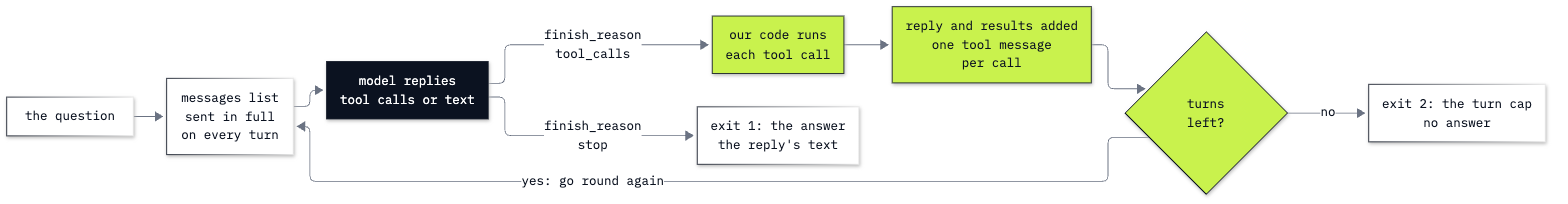

In [3]:
from IPython.display import Image

Image("resources/lab03_agent_loop.png", width=760)

---

## Part A: Run the loop over three lookups that depend on each other

Chinook is a small online music shop. Its data is `data/chinook.db`, a SQLite file with the customers, their
invoices and the support reps who look after them. A rep at the desk asks things like:

> How many invoices does Helena Holý have, what do they add up to, and who is her support rep?

The question asks for three facts, and they are in three tables. We write one small function for each lookup and
call them ourselves first, so we know the right answers before any model is involved.

### The three lookups

- `find_customer(name)` finds a customer by full name and returns their `customer_id`. It returns a **list**,
  because two customers could share a name. An empty list means nobody has exactly that name.
- `get_invoices(customer_id)` counts that customer's invoices and adds up their total.
- `get_support_rep(customer_id)` names the rep who looks after them.

In the first lines, `mode=ro` opens the database **read-only**, so no tool can change the shop's data; `uri=True` lets
us pass `?mode=ro` in the path. `check_same_thread=False` lets another thread use the connection. Agent frameworks that run tools on their own threads need it; nothing in this notebook does. In the SQL, `||` joins two strings: `FirstName || ' ' || LastName` is the customer's full name.

Each function has type hints and a docstring. We will copy the docstrings into the tool schemas, because the model
reads them to choose a tool.

In [4]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

We answer the rep's question by hand. `find_customer` returns a list, so `[0]` takes its first match.

In [5]:
customer = find_customer("Helena Holý")[0]

print(customer)
print(get_invoices(customer["customer_id"]))
print(get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


These are the facts every answer in this notebook is checked against:

| Customer | `customer_id` | Invoices | Total | Support rep |
|---|---|---|---|---|
| Helena Holý | 6 | 7 | \$49.62 | Steve Johnson |

**Notice** the order the lookups need. `get_invoices` and `get_support_rep` take a `customer_id`, and only
`find_customer` can supply it. Whoever answers the question has to call `find_customer` first and wait for its
result. That is why this question cannot be answered with one tool call, and why it needs a loop.

### One schema per lookup

The model never sees our Python. For each function we send a description, a **tool schema**. Here is the one for
`find_customer`, written out in full:

- `name`: what the model writes to ask for this tool.
- `description`: the first line of the docstring. The model chooses a tool by reading this.
- `parameters`: the arguments, as a JSON Schema. Here one string called `name`, described by the docstring's
  `Args:` line.
- `strict: True`: the model's arguments must match the schema exactly. Strict mode needs every argument listed in
  `required` and `additionalProperties` set to `False`.

In [6]:
find_customer_tool = {
    "type": "function",
    "function": {
        "name": "find_customer",
        "description": "Find a shop customer by full name. Returns a list of matches with their customer_id.",
        "parameters": {
            "type": "object",
            "properties": {
                "name": {"type": "string", "description": "First and last name, for example 'Ana Silva'."}
            },
            "required": ["name"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

The other two schemas have the same shape. Each takes one whole number, the `customer_id`. `TOOLS` is the list we
will send with every request.

In [7]:
get_invoices_tool = {
    "type": "function",
    "function": {
        "name": "get_invoices",
        "description": "Count a customer's invoices and add up their total in US dollars.",
        "parameters": {
            "type": "object",
            "properties": {"customer_id": {"type": "integer"}},
            "required": ["customer_id"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

get_support_rep_tool = {
    "type": "function",
    "function": {
        "name": "get_support_rep",
        "description": "Name the support rep who looks after a customer.",
        "parameters": {
            "type": "object",
            "properties": {"customer_id": {"type": "integer"}},
            "required": ["customer_id"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

TOOLS = [find_customer_tool, get_invoices_tool, get_support_rep_tool]
print([tool["function"]["name"] for tool in TOOLS])

['find_customer', 'get_invoices', 'get_support_rep']


### A dictionary from tool names to functions

On the envelope hunt there was one tool, so every call went to the same function. With three tools, our code has to
run the function the model named. `FUNCTIONS` maps each tool name to the Python function that may run for it.

`run_tool` takes what a tool call carries, a name and a string of JSON arguments, and does three things:

1. looks the function up by its name;
2. turns the arguments into a dictionary with `json.loads`, and calls the function with them (`**` passes
   `{"name": "Helena Holý"}` as `name="Helena Holý"`);
3. returns the result as text, because a tool result is sent to the model as text. `json.dumps` writes the list or
   dictionary as JSON, and `ensure_ascii=False` keeps the `ý` readable.

We try it on a call we type ourselves.

In [8]:
FUNCTIONS = {
    "find_customer": find_customer,
    "get_invoices": get_invoices,
    "get_support_rep": get_support_rep,
}


def run_tool(name, arguments):
    function = FUNCTIONS[name]
    result = function(**json.loads(arguments))
    return json.dumps(result, ensure_ascii=False)


print(run_tool("find_customer", '{"name": "Helena Holý"}'))

[{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


The same record as before, now as a string of JSON. This is what will go into a `tool` message.

### The loop, with one line printed per turn

`SYSTEM` is the system prompt. It tells the model to look every fact up and never to answer from memory: we want
each fact in a reply to come from a lookup that we can check.

`run_loop` is the five steps from the top of this notebook. Two `print` lines let us watch a run:

- one line per **turn** (one call to the model): its `finish_reason`, the tokens the call sent
  (`usage.prompt_tokens`), the tokens the model wrote (`usage.completion_tokens`), and the tools the reply asked
  for;
- one line per tool call: the call and what our function returned.

`reply.tool_calls or []` gives an empty list when the reply has no tool calls, where `tool_calls` is `None`. The
numbers after the colons in the `print` line (`:10`, `:4`, `:3`) only pad the columns, so the turns line up.

In [9]:
SYSTEM = (
    "You help the support reps of a music shop. Look up every fact with the tools; "
    "never answer from memory. Answer in one or two sentences."
)


def run_loop(question, max_turns=6):
    messages = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": question},
    ]

    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit
        )
        reply = response.choices[0].message
        messages.append(reply)

        asked = [call.function.name for call in reply.tool_calls or []]
        print(f"turn {turn}: {response.choices[0].finish_reason:10} | prompt tokens {response.usage.prompt_tokens:4}"
              f" | output tokens {response.usage.completion_tokens:3} | asks for {asked}")

        # Exit 1: the model answered
        if response.choices[0].finish_reason != "tool_calls":
            return reply.content

        for call in reply.tool_calls:
            result = run_tool(call.function.name, call.function.arguments)
            print(f"        {call.function.name}({call.function.arguments}) -> {result}")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

    # Exit 2: the turn cap stopped the loop, and there is no answer
    return None

Before you run it: how many turns will Helena's question take, and which lookups will each turn ask for?

In [10]:
HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

print(run_loop(HELENA))

turn 1: tool_calls | prompt tokens  259 | output tokens  20 | asks for ['find_customer']
        find_customer({"name":"Helena Holý"}) -> [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


turn 2: tool_calls | prompt tokens  316 | output tokens  51 | asks for ['get_invoices', 'get_support_rep']
        get_invoices({"customer_id": 6}) -> {"customer_id": 6, "invoice_count": 7, "total": 49.62}
        get_support_rep({"customer_id": 6}) -> {"customer_id": 6, "support_rep": "Steve Johnson"}


turn 3: stop       | prompt tokens  419 | output tokens  24 | asks for []
Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Three turns:

1. The model asked for `find_customer`, because the other two lookups need a `customer_id`.
2. Once it had the id, 6, it asked for `get_invoices` and `get_support_rep` **in the same reply**. Neither depends
   on the other, so nothing made it wait. The `for` loop over `reply.tool_calls` ran both.
3. It wrote the answer: 7 invoices, \$49.62 and Steve Johnson, the three facts of our table.

On the envelope hunt every reply held one call. Here turn 2 held two, and that saved a turn: with one call per
reply this question would take four.

**Read the `prompt tokens` column:** 259, 316 and 419. The count grows because every call sends the whole list
again, with the tool calls and the results of the turns before. The model keeps nothing between calls. The `output
tokens` are what the model wrote on each turn: 20 for one tool call, 51 for two, and 24 for the answer.

**Checkpoint A.** The lookups give Helena `customer_id` 6, 7 invoices, \$49.62 and Steve Johnson. The loop answers
her question with the same three facts in three turns: `find_customer`, then `get_invoices` and `get_support_rep`
in one reply, then the answer. The prompt tokens grow from one turn to the next.

---

## Part B: Return a tool's error to the model as a result

Tools fail. A database is down, a request times out, an argument is wrong. So far our loop has only seen tools that
work. What does it do with one that does not?

We make the database fail in the simplest way: we close the connection, as if the database had gone away. Then we
call a lookup by hand. The `try` and `except` catch the error so that we can print it.

In [11]:
conn.close()

try:
    find_customer("Helena Holý")
except sqlite3.Error as error:
    print(type(error).__name__, "|", error)

ProgrammingError | Cannot operate on a closed database.


The lookup raised a `ProgrammingError`: *Cannot operate on a closed database.*

Inside `run_loop`, that error would leave `run_tool` and end the whole run with a traceback. The rep would get
nothing. The `messages` list would be left broken too: its last item would be the model's request for a tool, with
no `tool` message to answer it, and the API refuses to continue from a list like that.

The usual fix is to catch the error and send it back **as the tool's result**, as text the model can read. The new
`run_tool` does that in two places:

- A tool name that is not in `FUNCTIONS` gets a sentence back, where the first version would have failed on the
  dictionary lookup.
- `except Exception` catches any error the function raises. `type(error).__name__` is the error's class name, so
  the text says what kind of failure it was.

In [12]:
def run_tool(name, arguments):
    if name not in FUNCTIONS:
        return f"Error: there is no tool named {name}"

    try:
        result = FUNCTIONS[name](**json.loads(arguments))
    except Exception as error:
        return f"Error: {type(error).__name__}: {error}"

    return json.dumps(result, ensure_ascii=False)


print(run_tool("find_customer", '{"name": "Helena Holý"}'))

Error: ProgrammingError: Cannot operate on a closed database.


The error is now a string, like any other tool result. `run_loop` looks `run_tool` up by its name each time it
runs, so it uses this new version from here on.

The database is still closed. Before you run Helena's question again: what will the model do when a lookup comes
back with an error?

In [13]:
print(run_loop(HELENA))

turn 1: tool_calls | prompt tokens  259 | output tokens  20 | asks for ['find_customer']
        find_customer({"name":"Helena Holý"}) -> Error: ProgrammingError: Cannot operate on a closed database.


turn 2: tool_calls | prompt tokens  302 | output tokens  20 | asks for ['find_customer']
        find_customer({"name":"Helena Holý"}) -> Error: ProgrammingError: Cannot operate on a closed database.


turn 3: stop       | prompt tokens  345 | output tokens  26 | asks for []
I’m unable to look up Helena Holý’s invoices or support rep right now because the customer database is unavailable.


The run did not crash. It took three turns:

1. The model asked for `find_customer`. Our function failed, and the error went back as the tool's result.
2. The model read the error and asked for `find_customer` once more, with the same name. The same error went back.
3. The model stopped asking and wrote a reply for the rep: it cannot look up Helena's invoices or her support rep,
   because the customer database is unavailable.

The loop kept going through a failing tool. The run ended through its normal exit, and the rep got a sentence they
can act on.

**Notice** that the model tried again once. We wrote no retry: the model chose it after reading the error. Had it
kept trying, the turn cap would have ended the run.

**Important:** the model reads an error the way it reads any result, so write errors for it. *Cannot operate on a
closed database* says what is wrong, and the reply could pass that on. An error that says only `KeyError: 6` would
leave the model, and then the rep, guessing.

We open the database again before we go on. The lookups read the name `conn` each time they run, so a new
connection under the same name is enough.

In [14]:
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)

print(find_customer("Helena Holý"))

[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]


**Checkpoint B.** With the connection closed, `run_tool` returns `Error: ProgrammingError: Cannot operate on a
closed database.` as text. The run does not crash: the error goes back to the model as a tool result, and the reply
tells the rep that the database cannot be reached. After the last cell `find_customer` finds Helena again.

---

## Part C: Find and fix a run that ends normally without an answer, on a near-miss name

The failures that are hardest to see do not raise anything. A rep types the customer's name without its accent,
*Helena Holy*, as a keyboard without Czech letters writes it. Our lookup matches names exactly:

In [15]:
print(find_customer("Helena Holy"))

[]


An empty list. Nothing failed: this is a valid result, and it says that nobody has exactly this name.

Before you run the loop on it: will the model try another spelling, or stop?

In [16]:
HELENA_NO_ACCENT = "How many invoices does Helena Holy have, what do they add up to, and who is her support rep?"

print(run_loop(HELENA_NO_ACCENT))

turn 1: tool_calls | prompt tokens  258 | output tokens  19 | asks for ['find_customer']
        find_customer({"name":"Helena Holy"}) -> []


turn 2: stop       | prompt tokens  289 | output tokens  38 | asks for []
I couldn’t find a customer record for Helena Holy, so I can’t verify her invoice count, total, or support rep. Could you check the spelling of her name?


Two turns. The model asked for `find_customer` with *Helena Holy*, exactly as the rep typed it, and the result was
`[]`. On turn 2 it wrote a reply: it could not find a customer record for Helena Holy, so it cannot give her
invoices or her rep, and it asks the rep to check the spelling.

Now look at the run the way our code sees it. The last `finish_reason` is `stop`, and `run_loop` returned text.
**By every sign the loop has, this run succeeded.** And the reply is wrong about the shop: Helena is in the database
with 7 invoices, under a name that differs by one accent.

**Key lesson:** `stop` means the model stopped asking for tools. It does not mean the question was answered. The loop
cannot tell a good answer from a polite "not found", because both end the same way.

**Why does the model stop?** The empty list is all it got. It cannot see the `customers` table, and no tool lets it
list names, so "no such customer" is a fair reading of `[]`. Nothing is wrong with the loop or with the model's
reading. The problem is the tool's result: it says that nobody matched, and nothing about names that are close.

### A tool result that says which names are close

When the exact match finds nobody, the tool can say which names come close. Python's standard library has a
function for that: `difflib.get_close_matches(word, possibilities, n, cutoff)` scores how alike `word` and each
possibility are, from 0 (nothing in common) to 1 (identical), and returns at most `n` of those that score `cutoff`
or more, the best first. First on three names that we can check by eye:

In [17]:
import difflib

print(difflib.get_close_matches("Helena Holy", ["Helena Holý", "Hugh O'Reilly", "Puja Srivastava"], n=3, cutoff=0.8))

['Helena Holý']


Only *Helena Holý* comes back: ten of its eleven characters match *Helena Holy*. Its score is 0.91: twice the 10
matching characters, divided by the 22 characters of the two names together. The other two names share a few letters
with it and fall under the cutoff of 0.8.

Now the same check against every customer name in the shop. `find_customer_or_close` calls our exact lookup first.
When that finds nobody, it adds the close names. It returns a dictionary with two named fields, `matches` and
`close_names`, because the model reads the field names as well as the values.

In [18]:
ALL_NAMES = [row[0] for row in conn.execute("SELECT FirstName || ' ' || LastName FROM customers")]


def find_customer_or_close(name: str) -> dict:
    """Find a shop customer by full name. With no exact match, list the customer names that are close."""
    matches = find_customer(name)
    if matches:
        return {"matches": matches}
    return {"matches": [], "close_names": difflib.get_close_matches(name, ALL_NAMES, n=3, cutoff=0.8)}


print(len(ALL_NAMES), "customer names")
print(find_customer_or_close("Helena Holy"))
print(find_customer_or_close("Helena Holý"))

59 customer names
{'matches': [], 'close_names': ['Helena Holý']}
{'matches': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}


Without the accent, `matches` is empty and `close_names` holds the one near spelling. With the accent, the exact
match comes back as before.

We put the new function in `FUNCTIONS` under the old name. The schema does not change: the model still asks for
`find_customer`, and only what comes back is different. Then the same question, without the accent.

In [19]:
FUNCTIONS["find_customer"] = find_customer_or_close

print(run_loop(HELENA_NO_ACCENT))

turn 1: tool_calls | prompt tokens  258 | output tokens  19 | asks for ['find_customer']
        find_customer({"name":"Helena Holy"}) -> {"matches": [], "close_names": ["Helena Holý"]}


turn 2: tool_calls | prompt tokens  303 | output tokens  20 | asks for ['find_customer']
        find_customer({"name":"Helena Holý"}) -> {"matches": [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]}


turn 3: tool_calls | prompt tokens  362 | output tokens  51 | asks for ['get_invoices', 'get_support_rep']
        get_invoices({"customer_id": 6}) -> {"customer_id": 6, "invoice_count": 7, "total": 49.62}
        get_support_rep({"customer_id": 6}) -> {"customer_id": 6, "support_rep": "Steve Johnson"}


turn 4: stop       | prompt tokens  465 | output tokens  24 | asks for []
Helena Holy has 7 invoices totaling $49.62, and her support rep is Steve Johnson.


Four turns, and this time the three facts:

1. `find_customer` with *Helena Holy*. No match, and `close_names` holds *Helena Holý*.
2. `find_customer` again, now with the accent. The model took that spelling from the tool result, and it matched
   customer 6.
3. `get_invoices` and `get_support_rep` in one reply.
4. The answer: 7 invoices, \$49.62 and Steve Johnson.

Between the two runs the loop did not change, and neither did the model, the system prompt or the schema. **Only
the tool's result did.** An empty result answers a narrow question: is there an exact match? A result
that also says what is close gives the model what it needs for its next call.

**What this fix does not cover.** A name with more letters wrong can score under the cutoff and come back with an
empty `close_names`. And when `close_names` holds several names, the model should ask the rep which customer they
mean, not pick one. The Challenge works on a miss of this kind and on the case with several names.

**Checkpoint C.** With the exact lookup: `[]`, then a reply that says the customer could not be found, in a run
that ended with `stop`. With close names: `find_customer` twice (the second time with the accent), then the
invoices and the rep, then Helena's three facts.

---

## In production

- **The cap is a setting in every framework.** The frameworks that run this loop for us have the same second exit
  under names such as `max_turns` or a recursion limit. Find it and set it; some defaults are far higher than a
  support question needs.
- **Search that allows for spelling differences.** At scale the job of `close_names` is done by a search that ignores
  accents and case, or by a fuzzy search in the database.
- **Check that the answer is right, not only that the run ended.** A run that ended with `stop` can still be a wrong
  answer or a polite "not found". Teams test their agents on questions with known answers, and keep a record of every
  call, so that such runs are caught.

## What you can do now

- Give the loop several tools, with one schema each and a dictionary from tool names to functions (Part A).
- Read a run turn by turn: the tools each reply asked for, and the tokens each call sent (Part A).
- Catch a tool's error and return it to the model as a result (Part B).
- Say what `stop` tells us about a run and what it leaves open (Part C).
- Write a tool result that tells the model what is close when nothing matches (Part C).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| every lookup comes back as `Error: ProgrammingError: Cannot operate on a closed database.` | Part B closed the connection, and the cell that opens it again was skipped | run the last code cell of Part B |
| `sqlite3.OperationalError: unable to open database file` | `data/chinook.db` is missing from the repository folder | restore the file (clone the repository again, or `git checkout data/chinook.db`) |
| `BadRequestError: Error code: 400 - An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'.` | the list holds a reply that asked for a tool, and no `tool` message answers it | add one `tool` message for every call in `reply.tool_calls` before the next request |
| `BadRequestError: Error code: 400 - Function tools with reasoning_effort are not supported for <model> in /v1/chat/completions.` | on Chat Completions this model calls tools only when the reasoning effort is `none` | set `REASONING_EFFORT=none` in `models.env` and run the first cell again |

## Challenge

1. **A first name only.** A rep asks *Who is Mark's support rep?* The exact lookup finds nobody called *Mark*, and
   `close_names` comes back empty, because a first name alone is too far from any full name.
   - Write a lookup that, when there is no exact match and no close name, returns in `close_names` the customers
     whose first name or last name is the word given. Put it in `FUNCTIONS` under `find_customer` and ask the
     question. Expected: the tool result lists two customers, Mark Philips and Mark Taylor. Now read the reply: does
     it ask which Mark, or does it pick one? Ours picked Mark Philips without saying that there are two.
   - Add one sentence to the system prompt that tells the model what to do when a lookup returns more than one
     possible customer, and ask again. Expected: the reply names both Marks and asks the rep which one they mean.
2. **Say why the run ended.** Change `run_loop` so that it returns two things, the answer and the reason it stopped
   (`"answer"` or `"turn cap"`). Run Helena's question with `max_turns=2`.
   Expected: two turns, then `None` and `turn cap`. The lookups of turn 2 ran, and the model never read their
   results.

The worked solution, run with its outputs, is in `solved/03b_agent_loop_at_the_desk_solution.ipynb`.

## Going further

- **What a run costs.** The price of a run is its tokens times the prices in `models.env`, which are in US dollars
  per million tokens. Add up the `prompt tokens` column and the `output tokens` column of a run:

  $$\text{cost} = \frac{\text{prompt tokens} \times \text{input price} + \text{output tokens} \times \text{output price}}{1{,}000{,}000}$$

  For Part A's run, 259 + 316 + 419 = 994 prompt tokens and 20 + 51 + 24 = 95 output tokens, at the input and output
  prices in `models.env`, 0.10 and 0.50: (994 × 0.10 + 95 × 0.50) / 1,000,000 = 0.000147 US dollars. The prompt tokens
  are the larger part, and they grow with every turn, because each call sends the whole list again.
- **The other values of `finish_reason`.** Our loop treats everything that is not `tool_calls` as an answer. Two
  values deserve their own branch in real code: `length` (the reply was cut off at the output token limit, so the
  text is incomplete) and `content_filter` (the reply was withheld). Both end the loop through exit 1 today.
- **Why fewer turns are safer.** Every turn is one more chance for a wrong argument or a misread result. If each
  turn goes right 95 times in 100, and the turns do not affect each other, a run of $n$ turns goes right
  $0.95^n$ of the time: 0.86 for 3 turns, 0.74 for 6 and 0.60 for 10. The 0.95 is an example; nobody measured it
  on this model. The point is the direction: long runs fail more often than their single steps suggest.
- **The loop as plain text.** `03_extra_react.ipynb` in this folder builds the same loop with no `tools=` argument
  at all: the model writes its request as a line of text and our code reads it. This is the ReAct pattern, which
  native tool calls have replaced.

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, tool calls and sending results back
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `finish_reason`, `usage` and the message roles
- [OpenAI Agents SDK: running agents](https://openai.github.io/openai-agents-python/running_agents/): the same loop
  as a framework runs it, with `max_turns`
- [Python: `difflib`](https://docs.python.org/3/library/difflib.html): `get_close_matches`
- [Python: `sqlite3`](https://docs.python.org/3/library/sqlite3.html): opening a database read-only with a URI

Back to [notebook 1](03a_meet_the_agent_loop.ipynb). Next:
[Lab 04: What is an agent](../04_What_Is_An_Agent/README.md), which gives a name and a definition to what this loop
is.